In [23]:
import os
import tqdm
from tqdm.autonotebook import tqdm as notebook_tqdm
from typing import Collection
from qdrant_client import QdrantClient

client = QdrantClient(url="http://localhost:6333")

client.get_collections()

kb_collection = "rag_knowledge"

from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("BAAI/bge-small-zh-v1.5")

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

In [24]:
from rank_bm25 import BM25Okapi
import numpy as np

# 1. 获取 Qdrant 全部数据
points, _ = client.scroll(
    collection_name=kb_collection,
    limit=1000,
    with_payload=True,
    with_vectors=False
)

# 按文档编号和 Chunk 编号排序
points = sorted(
    points,
    key=lambda p: (
        str((p.payload or {}).get("document_id", "")),
        int((p.payload or {}).get("chunk_id", 0))
    )
)

# 2. 重建统一语料
documents = []
document_point_ids = []
document_metadata = []

for point in points:

    payload = point.payload or {}

    text = payload.get("text", "")

    if not text:
        continue

    documents.append(text)

    document_point_ids.append(point.id)

    document_metadata.append(payload.copy())


print("统一知识库重建完成")
print("Documents:", len(documents))
print("Point IDs:", len(document_point_ids))
print("Metadata:", len(document_metadata))

统一知识库重建完成
Documents: 7
Point IDs: 7
Metadata: 7


In [25]:
import torch
from sentence_transformers import CrossEncoder

device = "cuda" if torch.cuda.is_available() else "cpu"

reranker_model = CrossEncoder(
    "BAAI/bge-reranker-v2-m3",
    max_length=512,
    device=device
)

print("Device:", device)
print("Reranker loaded successfully!")

def rerank_documents(
    query,
    documents,
    top_k=3
):
    if not documents:
        return []

    pairs = [
        [query, doc["text"]]
        for doc in documents
    ]

    scores = reranker_model.predict(
        pairs,
        batch_size=16,
        show_progress_bar=False
    )

    reranked = []

    for doc, score in zip(documents, scores):
        item = doc.copy()
        item["rerank_score"] = float(score)
        reranked.append(item)

    reranked.sort(
        key=lambda x: x["rerank_score"],
        reverse=True
    )

    return reranked[:top_k]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Device: cuda
Reranker loaded successfully!


In [28]:
import re
import jieba
import numpy as np

def tokenize(text):
    # 统一英文字母大小写
    text = text.lower()

    # 保留专业缩写、数字和中文
    tokens = jieba.lcut(text)

    return [
        token.strip()
        for token in tokens
        if token.strip()
        and not re.fullmatch(r"\W+", token)
    ]
from rank_bm25 import BM25Okapi


tokenized_documents = [
    tokenize(doc)
    for doc in documents
]

bm25 = BM25Okapi(tokenized_documents)

print("BM25 重建成功")
print("Corpus size:", bm25.corpus_size)
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(
    "BAAI/bge-small-zh-v1.5"
)
document_embeddings = embedding_model.encode(
    documents,
    normalize_embeddings=True
)

BM25 重建成功
Corpus size: 7


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

In [45]:
def bm25_search(query, top_k=3):

    query_tokens = tokenize(query)

    scores = bm25.get_scores(query_tokens)

    ranked_ids = np.argsort(-scores)[:top_k]

    results = []

    for idx in ranked_ids:

        idx = int(idx)

        results.append({
            "id": idx,

            "point_id": document_point_ids[idx],

            "text": documents[idx],

            "metadata": document_metadata[idx].copy(),

            "score": float(scores[idx])
        })

    return results
def dense_search(query, top_k=3):

    query_embedding = embedding_model.encode(
        query,
        normalize_embeddings=True
    )

    scores = document_embeddings @ query_embedding

    ranked_ids = np.argsort(-scores)[:top_k]

    results = []

    for idx in ranked_ids:

        idx = int(idx)

        results.append({
            "id": idx,

            "point_id": document_point_ids[idx],

            "text": documents[idx],

            "metadata": document_metadata[idx].copy(),

            "score": float(scores[idx])
        })

    return results

# RRF
def reciprocal_rank_fusion(
    result_lists,
    rrf_k=60,
    top_k=3
):

    fused_scores = {}
    document_map = {}

    for results in result_lists:

        for rank, result in enumerate(results, start=1):

            doc_id = result["id"]

            fused_scores[doc_id] = (
                fused_scores.get(doc_id, 0.0)
                + 1.0 / (rrf_k + rank)
            )

            # 保存整个文档，而不只是文本
            document_map[doc_id] = result.copy()

    ranked_ids = sorted(
        fused_scores,
        key=lambda doc_id: (
            -fused_scores[doc_id],
            doc_id
        )
    )

    fused_results = []

    for doc_id in ranked_ids[:top_k]:

        item = document_map[doc_id].copy()

        item["score"] = fused_scores[doc_id]

        fused_results.append(item)

    return fused_results

In [46]:
def hybrid_search(
    query,
    top_k=3,
    candidate_k=8,
    rrf_k=60
):
    bm25_results = bm25_search(
        query,
        top_k=candidate_k
    )

    dense_results = dense_search(
        query,
        top_k=candidate_k
    )

    fused_results = reciprocal_rank_fusion(
        result_lists=[
            bm25_results,
            dense_results
        ],
        rrf_k=rrf_k,
        top_k=top_k
    )

    return fused_results

def hybrid_rerank_search(
    query,
    top_k=3,
    candidate_k=8,
    rrf_k=60
):

    # 1. BM25
    bm25_results = bm25_search(
        query,
        top_k=candidate_k
    )

    # 2. Dense
    dense_results = dense_search(
        query,
        top_k=candidate_k
    )

    # 3. RRF
    candidates = reciprocal_rank_fusion(
        result_lists=[
            bm25_results,
            dense_results
        ],
        rrf_k=rrf_k,
        top_k=candidate_k
    )

    # 保存原始候选文档
    candidate_map = {
        item["id"]: item
        for item in candidates
    }

    # 4. Reranker
    reranked = rerank_documents(
        query=query,
        documents=candidates,
        top_k=top_k
    )

    # 5. 恢复完整元数据
    final_results = []

    for item in reranked:

        doc_id = item["id"]

        original = candidate_map[doc_id].copy()

        original.update(item)

        # 兼容原始拼写错误
        metadata = original.get("metadata", {})

        if "catergory" in metadata:
            metadata["category"] = metadata["catergory"]

        original["metadata"] = metadata

        final_results.append(original)

    return final_results

In [47]:
from langchain_core.tools import tool
import json

@tool
def search_knowledge_base(
    query: str,
    top_k: int = 4
) -> str:
    """检索专业知识库，返回相关文档及其来源。"""

    results = hybrid_rerank_search(
        query=query,
        top_k=top_k
    )

    output = []

    for rank, doc in enumerate(results, 1):

        metadata = doc.get("metadata", {})

        output.append({
            "rank": rank,
            "text": doc["text"],
            "source": metadata.get("source", "未知"),
            "page": metadata.get("page", "未知"),
            "year": metadata.get("year", "未知"),
            "region": metadata.get("region", "未知"),
            "point_id": doc.get("point_id"),
            "rerank_score": doc.get("rerank_score")
        })

    return json.dumps(
        output,
        ensure_ascii=False,
        indent=2
    )

In [48]:
assert len(documents) == len(document_point_ids)
assert len(documents) == len(document_metadata)
assert len(documents) == bm25.corpus_size
assert len(documents) == document_embeddings.shape[0]

for i in range(len(documents)):

    print("=" * 60)

    print("内部索引:", i)
    print("Qdrant ID:", document_point_ids[i])
    print("文档:", documents[i])
    print("来源:", document_metadata[i].get("source"))
    print("页码:", document_metadata[i].get("page"))

内部索引: 0
Qdrant ID: 0
文档: 持续降雨是诱发滑坡的重要因素之一。
来源: landslide_report.pdf
页码: 12
内部索引: 1
Qdrant ID: 1
文档: 降雨入渗会导致土体含水率增加，
并可能造成孔隙水压力升高，从而降低土体有效应力和抗剪强度。
来源: landslide_report.pdf
页码: 12
内部索引: 2
Qdrant ID: 2
文档: 地下水位变化同样会影响边坡稳定性。
来源: landslide_report.pdf
页码: 12
内部索引: 3
Qdrant ID: 3
文档: 当地下水位升高时，
坡体内部孔隙水压力可能增加，从而减小有效应力，
使边坡更容易发生失稳。
来源: landslide_report.pdf
页码: 12
内部索引: 4
Qdrant ID: 4
文档: 坡度是影响滑坡发生的重要地形条件。
来源: landslide_report.pdf
页码: 12
内部索引: 5
Qdrant ID: 5
文档: 较大的坡度通常意味着更大的下滑力，
但滑坡发生还受到岩性、土体结构、植被覆盖和水文条件等因素共同控制。
来源: landslide_report.pdf
页码: 12
内部索引: 6
Qdrant ID: 6
文档: 在光伏功率预测中，太阳辐射是最重要的气象因素之一。云量、温度、湿度和风速都会影响光伏组件的发电效率。
来源: landslide_report.pdf
页码: 12


In [49]:
rag_test = search_knowledge_base.invoke({
    "query": "地下水位升高为什么会影响边坡稳定性？",
    "top_k": 4
})

print(rag_test)

[
  {
    "rank": 1,
    "text": "当地下水位升高时，\n坡体内部孔隙水压力可能增加，从而减小有效应力，\n使边坡更容易发生失稳。",
    "source": "landslide_report.pdf",
    "page": 12,
    "year": 2026,
    "region": "Kentucky",
    "point_id": 3,
    "rerank_score": 0.9989150762557983
  },
  {
    "rank": 2,
    "text": "地下水位变化同样会影响边坡稳定性。",
    "source": "landslide_report.pdf",
    "page": 12,
    "year": 2026,
    "region": "Kentucky",
    "point_id": 2,
    "rerank_score": 0.9933156371116638
  },
  {
    "rank": 3,
    "text": "降雨入渗会导致土体含水率增加，\n并可能造成孔隙水压力升高，从而降低土体有效应力和抗剪强度。",
    "source": "landslide_report.pdf",
    "page": 12,
    "year": 2026,
    "region": "Kentucky",
    "point_id": 1,
    "rerank_score": 0.011356343515217304
  },
  {
    "rank": 4,
    "text": "较大的坡度通常意味着更大的下滑力，\n但滑坡发生还受到岩性、土体结构、植被覆盖和水文条件等因素共同控制。",
    "source": "landslide_report.pdf",
    "page": 12,
    "year": 2026,
    "region": "Kentucky",
    "point_id": 5,
    "rerank_score": 0.008624300360679626
  }
]


In [50]:
RAG_AGENT_SYSTEM_PROMPT = """
你是一名专业的地质灾害与水文气象分析助手。

你可以调用以下工具：
1. search_knowledge_base：检索专业知识库。
2. calculate_effective_rainfall：计算有效降雨量。
3. calculate_rainfall_statistics：统计降雨数据。

回答规则：

一、知识检索
当用户提出专业知识问题时，优先调用知识库。

二、证据约束
1. 依据检索到的文档回答。
2. 不得编造文献名称、年份和页码。
3. 不得将模型自身推测描述为文献结论。
4. 如果知识库没有相关证据，明确说明。

三、文献引用
1. 每个重要结论都应有对应的证据编号。
2. 引用格式为 [S1]、[S2]。
3. 最后列出来源文件名和页码。
4. 不得虚构来源。

四、计算任务
需要计算时必须调用计算工具。
区分计算结果和文献证据。
不得将有效降雨量直接等同于实际径流量。

五、回答结构
1. 分析结论
2. 机制解释
3. 参考依据
4. 数据局限性
"""

In [55]:
from typing import Annotated
from typing_extensions import TypedDict

from langchain_core.messages import (
    SystemMessage,
    HumanMessage,
    AIMessage,
    ToolMessage
)

from langchain_core.tools import tool

from langgraph.graph import (
    StateGraph,
    START,
    END,
    MessagesState
)

from langgraph.prebuilt import (
    ToolNode,
    tools_condition
)

In [52]:
# 调用 LLM 生成答案
import os
from langchain_deepseek import ChatDeepSeek
from langchain_community.chat_models import ChatTongyi
from langchain_openai import ChatOpenAI
from langchain.chat_models import init_chat_model
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from dotenv import load_dotenv
from rich import print as rprint
import time


load_dotenv(override=True)

DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")

llmodel_deepseek = init_chat_model(
    model = "deepseek-flash",
    api_key = DEEPSEEK_API_KEY,
    api_base = DEEPSEEK_BASE_URL,

)



In [53]:
class RAGAgentState(MessagesState):
    pass

In [56]:
from langchain_core.tools import tool

@tool
def calculate_effective_rainfall(
    precipitation_mm: float,
    infiltration_mm: float
) -> float:
    """
    计算有效降雨量。

    Args:
        precipitation_mm: 总降水量，单位mm。
        infiltration_mm: 入渗量，单位mm。

    Returns:
        有效降雨量，单位mm。
    """

    if precipitation_mm < 0 or infiltration_mm < 0:
        raise ValueError("降水量和入渗量不能为负数")

    if infiltration_mm > precipitation_mm:
        raise ValueError("入渗量不能大于总降水量")

    return precipitation_mm - infiltration_mm

tools = [
    calculate_effective_rainfall
]

for t in tools:
    print(t.name)
    print(t.description)

@tool
def calculate_rainfall_statistics(
    precipitation: list[float]
) -> dict:
    """
    统计一段时间内的降雨数据。

    Args:
        precipitation: 每日降水量列表，单位mm。

    Returns:
        总降水量、平均降水量、最大日降水量、
        降雨天数。
    """

    if not precipitation:
        raise ValueError("降水数据不能为空")

    if any(p < 0 for p in precipitation):
        raise ValueError("降水量不能为负数")

    return {
        "total_rainfall": sum(precipitation),
        "mean_rainfall": sum(precipitation) / len(precipitation),
        "max_rainfall": max(precipitation),
        "rainy_days": sum(p > 0.1 for p in precipitation),
        "total_days": len(precipitation)
    }


from langchain_core.messages import ToolMessage

# 建立工具名称与工具对象的映射
tool_map = {
    tool.name: tool
    for tool in tools
}

# # 获取模型生成的工具调用
# for tool_call in response.tool_calls:

#     tool_name = tool_call["name"]
#     tool_args = tool_call["args"]

#     # 找到对应工具
#     selected_tool = tool_map[tool_name]

#     # 执行工具
#     tool_result = selected_tool.invoke(tool_args)

#     print("工具名称:", tool_name)
#     print("工具参数:", tool_args)
#     print("执行结果:", tool_result)

calculate_effective_rainfall
计算有效降雨量。

Args:
    precipitation_mm: 总降水量，单位mm。
    infiltration_mm: 入渗量，单位mm。

Returns:
    有效降雨量，单位mm。


In [57]:
agent_tools = [
    search_knowledge_base,
    calculate_effective_rainfall,
    calculate_rainfall_statistics
]

print("已注册工具：")

for t in agent_tools:
    print("-", t.name)

rag_agent_model = llmodel_deepseek.bind_tools(
    agent_tools
)

print("Agent 模型工具绑定完成")

已注册工具：
- search_knowledge_base
- calculate_effective_rainfall
- calculate_rainfall_statistics
Agent 模型工具绑定完成


In [58]:
def rag_agent_node(state: RAGAgentState):

    messages = state["messages"]

    # 避免重复添加 SystemMessage
    conversation_messages = [
        msg for msg in messages
        if not isinstance(msg, SystemMessage)
    ]

    model_messages = [
        SystemMessage(
            content=RAG_AGENT_SYSTEM_PROMPT
        )
    ] + conversation_messages

    # 调用绑定工具的 DeepSeek
    response = rag_agent_model.invoke(
        model_messages
    )

    return {
        "messages": [response]
    }

In [60]:
rag_tool_node = ToolNode(
    agent_tools
)

print("ToolNode 创建完成")

def rag_agent_router(state: RAGAgentState):

    last_message = state["messages"][-1]

    # 如果模型发起工具调用
    if isinstance(last_message, AIMessage):
        if last_message.tool_calls:
            return "tools"

    # 没有工具调用，结束本轮
    return END

# 1. 创建工作流
rag_builder = StateGraph(RAGAgentState)


# 2. 添加节点
rag_builder.add_node(
    "agent",
    rag_agent_node
)

rag_builder.add_node(
    "tools",
    rag_tool_node
)


# 3. 设置入口
rag_builder.add_edge(
    START,
    "agent"
)


# 4. 设置条件路由
rag_builder.add_conditional_edges(
    "agent",
    rag_agent_router,
    {
        "tools": "tools",
        END: END
    }
)


# 5. 工具执行完毕后返回 Agent
rag_builder.add_edge(
    "tools",
    "agent"
)


# 6. 编译工作流
rag_agent_graph = rag_builder.compile()


print("RAG Agent 工作流创建成功！")

ToolNode 创建完成
RAG Agent 工作流创建成功！


In [61]:
query = """
地下水位升高为什么会影响边坡稳定性？

请结合知识库中的资料：
1. 解释具体作用机制。
2. 给出文献引用。
3. 标明原始文件名和页码。
4. 区分直接证据和推理解释。
"""

result = rag_agent_graph.invoke({
    "messages": [
        HumanMessage(content=query)
    ]
})

print(result["messages"][-1].content)

## 一、分析结论

知识库中的证据主要支持**核心机制**：地下水位升高会使坡体内部孔隙水压力增加，进而减小有效应力，使边坡更容易失稳 [S1]。这是一条直接证据；同一文献还用降雨入渗路径（含水率增加→孔隙水压力升高→有效应力下降→抗剪强度降低）来佐证这一链条 [S2]，并把“地下水位变化会影响边坡稳定性”作为一般性陈述提出 [S3]。

不过需要明确：知识库**没有提供**定量关系（如安全系数随水位变化的降幅、抗剪强度参数 c、φ 的具体衰减值）、没有涉及动水压力、静水压力、浮托力、软化崩解等其他机制的讨论，也没有给出具体案例的监测数据。因此，除以下列出的证据之外，其余机制解释属于**基于土力学原理的推理解释**，不属于文献结论。

## 二、机制解释

**（一）文献直接支持的机制链（[S1]，直接证据）**

地下水位升高 → 坡体内部孔隙水压力增加 → 有效应力减小 → 边坡抗失稳能力下降、更易失稳。

其力学含义是：土体骨架承担的有效应力等于总应力减去孔隙水压力。孔隙水压力上升会“顶托”土颗粒、削弱颗粒间的接触压力，从而降低摩擦所提供的抗力。

**（二）降雨入渗的平行路径（[S2]，直接证据，但以降雨为起点）**

降雨入渗 → 土体含水率增加 → 孔隙水压力升高 → 有效应力与抗剪强度降低。该条与 [S1] 指向同一力学环节（孔隙水压力—有效应力—强度），因此可作为 [S1] 的机制佐证；但需注意其**主语是降雨入渗而非地下水位**，不可直接替换表述。

**（三）以下为推理解释，非文献结论**

依据 [S1][S2] 的机制框架并结合一般土力学原理，还可以定性推断：有效应力下降会使摩尔–库仑强度包线上的可用抗剪强度降低；水位上升还可能减小潜在滑体的有效自重（浮托效应）；水位变动时的渗流会产生指向坡外的动水压力；某些土体饱水后发生软化、崩解，强度参数进一步劣化。**这些内容知识库中均无对应原文，属于推理，若需写入报告必须另行补充文献或实测依据。**

**（四）控制因素非单一（[S5]，直接证据）**

文献明确指出，滑坡发生受岩性、土体结构、植被覆盖和水文条件等因素共同控制，坡度只是重要地形条件之一 [S4][S5]。因此水位升高应理解为“降低稳定裕度的促发因素”，而非唯一决定因素。

## 三、参考依据

| 编号 | 内容要点 | 来源文件 

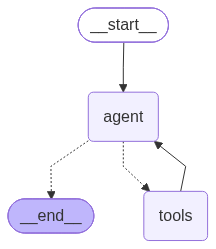

In [62]:
from IPython.display import Image, display

display(
    Image(
        rag_agent_graph.get_graph().draw_mermaid_png()
    )
)

In [64]:
query = """
某地区7天降雨量分别为：
12、25、0、38、45、8、15 mm。

已知总入渗量为35 mm。

请计算：
1. 总降雨量；
2. 平均日降雨量；
3. 最大日降雨量；
4. 有效降雨量。
"""

result = rag_agent_graph.invoke({
    "messages": [
        HumanMessage(content=query)
    ]
})

print(result["messages"][-1].content)

## 一、分析结论（计算结果）

| 项目 | 结果 | 说明 |
|---|---|---|
| 1. 总降雨量 | **143 mm** | 7日降雨量累加：12+25+0+38+45+8+15 |
| 2. 平均日降雨量 | **≈20.43 mm/d** | 143 ÷ 7（按统计工具计算，含无降雨日） |
| 3. 最大日降雨量 | **45 mm** | 出现在第5天 |
| 4. 有效降雨量 | **108 mm** | 143 − 35（总入渗量） |

补充统计信息：统计期内**降雨天数6天**，无降雨日1天（第3天，0 mm）。

## 二、机制解释

- 上述四项均为**计算工具输出结果**，不是文献结论。
- 有效降雨量按“总降水量扣除入渗量”的水量平衡方式计算，结果为108 mm。这一数值反映的是**未在计算时段内被土体入渗消耗的那部分降雨量**。
- 专业知识库检索到的相关证据表明：降雨入渗会提高土体含水率，可能使孔隙水压力升高，从而降低有效应力与抗剪强度 [S1]；并且持续降雨是诱发滑坡的重要因素之一 [S2]。这两点从机理上支持“降雨—入渗—坡体失稳”的因果链。不过，检索到的文献条目并未给出“有效降雨量”的具体定义、计算公式或阈值标准，因此本次计算所用的水量平衡方法属于工具口径，不能表述为文献推荐方法。

## 三、参考依据

- [S1] 降雨入渗使土体含水率增加、孔隙水压力升高、有效应力与抗剪强度降低 — `landslide_report.pdf`，第12页。
- [S2] 持续降雨是诱发滑坡的重要因素之一 — `landslide_report.pdf`，第12页。
- 计算依据：`calculate_rainfall_statistics`、`calculate_effective_rainfall` 工具输出。

来源文件：landslide_report.pdf（第12页，2026年，Kentucky 区域）。

## 四、数据局限性

1. **有效降雨量不等于径流量**：108 mm 只是“降水减入渗”的水量差额，未考虑蒸散发、地表填洼、壤中流、地下径流和坡面汇流过程，不能当作实际径流量或坡面来水量使用。
2. **入渗量取为定值35 mm**：未按逐日雨强分配，也未考虑土壤前期含水率、下渗能力随时间衰减和植被截留，